# Dana’s Bakery: deterministic LangGraph orders

Purpose: translate Dana’s story into a graph with validation, bounded substitution, pricing, delivery and a customer reply.

Prerequisites: a fresh Google Colab Python runtime with internet for package installation and Mermaid rendering. No API key or LLM is used. Run **Runtime → Run all**. All amounts are in Israeli shekels.


In [ ]:
%pip install -q langgraph==1.2.20


## Rules and interpretation

| Product | Price | Stock per invocation |
|---|---:|---:|
| challah | 18 | 10 |
| babka | 45 | 0 |
| rugelach (one box) | 30 | 3 |
| sourdough | 25 | 4 |

- Croissants and unknown products are rejected. Quantity must be a positive Python integer; booleans are invalid.
- Substitute babka → rugelach → sourdough → challah, at most two alternatives. Each must cover the entire quantity. No partial orders; no successor to challah.
- Avi’s final rule overrides the earlier rule: 15% off goods strictly above 150, never Friday. Delivery is never discounted.
- Jerusalem delivery costs 20; blank city means pickup. Other cities become free pickup with an explanation.
- Strip whitespace and ignore capitalization in product, day and city. Require all four input fields, an English weekday and a string city.
- Each call uses the original stock independently. No inventory mutation or customer confirmation is simulated.
- Rejected orders retain the normalized original item, total 0 and pickup. Additional state fields are returned for transparency.
- Deterministic templates replace the conflicting AI-reply wish. Avi, the cat and neighborhood do not affect logic; Instagram is deferred.

## Graph sketch

```text
START → validate_order
  invalid → reject_order → compose_message → END
  valid → check_stock
    enough → calculate_price → determine_delivery → compose_message → END
    shortage with next item and attempts < 2 → suggest_alternative → check_stock
    otherwise → reject_order → compose_message → END
```


In [2]:
from typing import Literal, TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

PRICES = {"challah": 1800, "babka": 4500, "rugelach": 3000, "sourdough": 2500}
STOCK = {"challah": 10, "babka": 0, "rugelach": 3, "sourdough": 4}
NEXT_ITEM = {"babka": "rugelach", "rugelach": "sourdough", "sourdough": "challah"}
DAYS = {"Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"}

class OrderState(TypedDict, total=False):
    item: str
    quantity: int
    day: str
    city: str
    original_item: str
    substitution_count: int
    rejection_reason: str
    subtotal_agorot: int
    discount_agorot: int
    delivery_fee_agorot: int
    status: Literal["accepted", "rejected"]
    delivery: Literal["pickup", "delivery"]
    total: float
    message: str
    steps: list[str]


def event(state: OrderState, text: str) -> list[str]:
    return state["steps"] + [text]


def validate_order(state: OrderState) -> dict:
    raw_item = state.get("item")
    item = raw_item.strip().lower() if isinstance(raw_item, str) else ""
    raw_day = state.get("day")
    day = raw_day.strip().capitalize() if isinstance(raw_day, str) else ""
    raw_city = state.get("city")
    city = raw_city.strip().casefold() if isinstance(raw_city, str) else ""
    quantity = state.get("quantity")
    reason = ""
    if item not in PRICES:
        reason = "We could not understand the product; please choose an item on our current menu."
    elif type(quantity) is not int or quantity <= 0:
        reason = "We could not understand the quantity; please enter a positive whole number."
    elif day not in DAYS:
        reason = "Please enter a valid English weekday."
    elif not isinstance(raw_city, str):
        reason = "Please enter a city name, or an empty string for pickup."
    # Reset derived fields so caller-supplied values cannot change an order's rules.
    return {"item": item, "original_item": item, "day": day, "city": city,
            "substitution_count": 0, "rejection_reason": reason,
            "subtotal_agorot": 0, "discount_agorot": 0,
            "delivery_fee_agorot": 0, "total": 0.0, "delivery": "pickup",
            "status": "rejected", "message": "",
            "steps": ["validate_order: " + (reason or "Input valid.")]}


def route_validation(state: OrderState) -> str:
    return "reject_order" if state["rejection_reason"] else "check_stock"


def check_stock(state: OrderState) -> dict:
    available = STOCK[state["item"]]
    enough = available >= state["quantity"]
    reason = ""
    if not enough and state["substitution_count"] >= 2:
        reason = "Neither of our two suggested alternatives has enough stock."
    elif not enough and state["item"] not in NEXT_ITEM:
        reason = "There is not enough stock and no further alternative is available."
    return {"rejection_reason": reason,
            "steps": event(state, f"check_stock: {state['item']}: need {state['quantity']}, have {available}; "
                           + ("enough." if enough else "insufficient."))}


def route_stock(state: OrderState) -> str:
    if STOCK[state["item"]] >= state["quantity"]:
        return "calculate_price"
    return "reject_order" if state["rejection_reason"] else "suggest_alternative"


def suggest_alternative(state: OrderState) -> dict:
    replacement = NEXT_ITEM[state["item"]]
    count = state["substitution_count"] + 1
    return {"item": replacement, "substitution_count": count,
            "steps": event(state, f"suggest_alternative: attempt {count}: {state['item']} -> {replacement}.")}


def calculate_price(state: OrderState) -> dict:
    subtotal = PRICES[state["item"]] * state["quantity"]
    discount = subtotal * 15 // 100 if subtotal > 15000 and state["day"] != "Friday" else 0
    return {"status": "accepted", "subtotal_agorot": subtotal, "discount_agorot": discount,
            "steps": event(state, f"calculate_price: goods {subtotal / 100:.2f}; discount {discount / 100:.2f}.")}


def determine_delivery(state: OrderState) -> dict:
    delivery = "delivery" if state["city"] == "jerusalem" else "pickup"
    fee = 2000 if delivery == "delivery" else 0
    explanation = "Outside Jerusalem; switched to pickup." if state["city"] and not fee else delivery + "."
    total = (state["subtotal_agorot"] - state["discount_agorot"] + fee) / 100
    return {"delivery": delivery, "delivery_fee_agorot": fee, "total": round(total, 2),
            "steps": event(state, f"determine_delivery: {explanation} Fee {fee / 100:.2f}.")}


def reject_order(state: OrderState) -> dict:
    return {"status": "rejected", "item": state["original_item"], "delivery": "pickup", "total": 0.0,
            "steps": event(state, "reject_order: " + state["rejection_reason"])}


def compose_message(state: OrderState) -> dict:
    if state["status"] == "rejected":
        message = "We're sorry, your order was rejected. " + state["rejection_reason"] + " We'd love to help you try again!"
    else:
        message = f"Thank you for ordering from Dana's Bakery! Your order is accepted: {state['quantity']} x {state['item']}. "
        if state["item"] != state["original_item"]:
            message += f"We substituted {state['item']} for {state['original_item']} to fill your whole order. "
        if state["discount_agorot"]:
            message += "Your baked goods received a 15% discount. "
        if state["delivery"] == "delivery":
            message += "Jerusalem delivery is included (20.00 shekels). "
        elif state["city"]:
            message += "We deliver only in Jerusalem, so we've switched your order to free pickup at the shop. "
        else:
            message += "Your order will be ready for free pickup at the shop. "
        message += f"Total: {state['total']:.2f} shekels. We look forward to seeing you!"
    return {"message": message, "steps": event(state, "compose_message: Customer reply prepared.")}


In [3]:
builder = StateGraph(OrderState)
for node in (validate_order, check_stock, suggest_alternative, calculate_price,
             determine_delivery, reject_order, compose_message):
    builder.add_node(node.__name__, node)
builder.add_edge(START, "validate_order")
builder.add_conditional_edges("validate_order", route_validation,
                              {name: name for name in ("check_stock", "reject_order")})
builder.add_conditional_edges("check_stock", route_stock,
                              {name: name for name in ("calculate_price", "suggest_alternative", "reject_order")})
builder.add_edge("suggest_alternative", "check_stock")
builder.add_edge("calculate_price", "determine_delivery")
builder.add_edge("determine_delivery", "compose_message")
builder.add_edge("reject_order", "compose_message")
builder.add_edge("compose_message", END)
graph = builder.compile()


## Graph drawing

This cell calls the required `draw_mermaid_png()` renderer, which uses an online Mermaid service. Order processing itself requires no network. If rendering fails, restore internet access and rerun this cell; the Mermaid text is printed for diagnosis, and the error is raised rather than hiding a missing drawing.


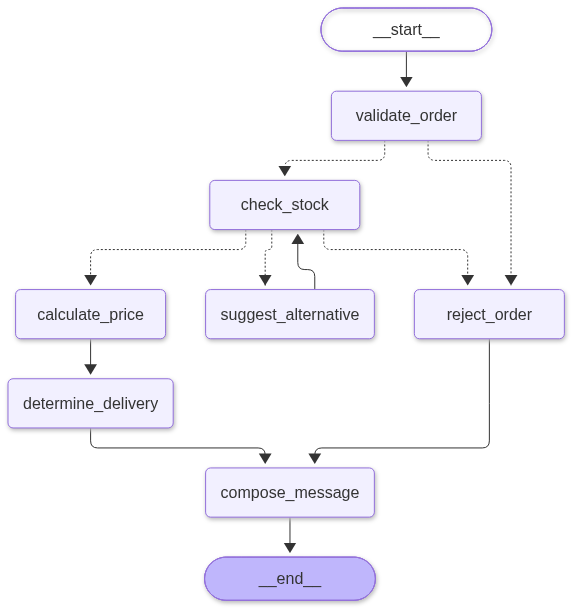

In [4]:
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print(graph.get_graph().draw_mermaid())
    raise


## Required example

Expected: accepted, 2 rugelach boxes after one substitution, Jerusalem delivery, total **80.00**. The diary records validation, stock checks, substitution, pricing, delivery and message preparation.


In [5]:
result = graph.invoke({"item": "babka", "quantity": 2,
                       "day": "Thursday", "city": "Jerusalem"})
for key in ("status", "item", "delivery", "total", "message", "steps"):
    print(f"{key}: {result[key]}")


status: accepted
item: rugelach
delivery: delivery
total: 80.0
message: Thank you for ordering from Dana's Bakery! Your order is accepted: 2 x rugelach. We substituted rugelach for babka to fill your whole order. Jerusalem delivery is included (20.00 shekels). Total: 80.00 shekels. We look forward to seeing you!
steps: ['validate_order: Input valid.', 'check_stock: babka: need 2, have 0; insufficient.', 'suggest_alternative: attempt 1: babka -> rugelach.', 'check_stock: rugelach: need 2, have 3; enough.', 'calculate_price: goods 60.00; discount 0.00.', 'determine_delivery: delivery. Fee 20.00.', 'compose_message: Customer reply prepared.']


## Deterministic test suite

Runner: **Google Colab → Runtime → Run all**. No external test files or API keys.

Each row specifies status, sold/original item, delivery, total, and number of substitutions. Tests cover direct acceptance, both substitution depths, cancellation at the limit and end of chain, discount versus Friday, pickup/delivery/fallback, and malformed input. Additional checks inspect exact trace order and every graph edge.

The exact 150-shekel boundary cannot be reached by a successful order with the story’s stock. Test the pricing node directly at 150 and 180 instead of modifying inventory.


In [6]:
def order(item="challah", quantity=1, day="Thursday", city=""):
    return {"item": item, "quantity": quantity, "day": day, "city": city}

# label, input, expected (status, item, delivery, total, substitutions)
cases = [
    ("first substitute", order("babka", 2, city="Jerusalem"), ("accepted", "rugelach", "delivery", 80.0, 1)),
    ("second substitute", order("babka", 4), ("accepted", "sourdough", "pickup", 100.0, 2)),
    ("two failures", order("babka", 5), ("rejected", "babka", "pickup", 0.0, 2)),
    ("discount", order(quantity=9, city="Jerusalem"), ("accepted", "challah", "delivery", 157.7, 0)),
    ("Friday", order(quantity=9, day="Friday", city="Jerusalem"), ("accepted", "challah", "delivery", 182.0, 0)),
    ("rugelach chain", order("rugelach", 5), ("accepted", "challah", "pickup", 90.0, 2)),
    ("sourdough chain", order("sourdough", 6), ("accepted", "challah", "pickup", 108.0, 1)),
    ("outside city", order("sourdough", 5, city="Tel Aviv"), ("accepted", "challah", "pickup", 90.0, 1)),
    ("chain end", order(quantity=11), ("rejected", "challah", "pickup", 0.0, 0)),
    ("direct stock", order("sourdough", 4), ("accepted", "sourdough", "pickup", 100.0, 0)),
    ("normalized", order(" CHALLAH ", 1, " thURsday ", " JERUSALEM "), ("accepted", "challah", "delivery", 38.0, 0)),
]
for item in ("pizza", "croissant", "croissants"):
    cases.append((item, order(item), ("rejected", item, "pickup", 0.0, 0)))
for quantity in (0, -2, 1.5, True, "2", None):
    cases.append((f"quantity {quantity!r}", order(quantity=quantity), ("rejected", "challah", "pickup", 0.0, 0)))
for day in ("Funday", "", None):
    cases.append((f"day {day!r}", order(day=day), ("rejected", "challah", "pickup", 0.0, 0)))
for city in (None, 123, []):
    cases.append((f"city {city!r}", order(city=city), ("rejected", "challah", "pickup", 0.0, 0)))
for field in ("item", "quantity", "day", "city"):
    data = order()
    del data[field]
    cases.append((f"missing {field}", data, ("rejected", "" if field == "item" else "challah", "pickup", 0.0, 0)))
for item in (None, 42, []):
    cases.append((f"item {item!r}", order(item), ("rejected", "", "pickup", 0.0, 0)))

required_keys = {"status", "item", "delivery", "total", "message", "steps"}
visited_edges = set()
for label, data, expected in cases:
    actual = graph.invoke(data)
    assert required_keys <= actual.keys(), label
    assert tuple(actual[key] for key in ("status", "item", "delivery", "total", "substitution_count")) == expected, (label, actual)
    assert actual == graph.invoke(data), f"Non-deterministic: {label}"
    names = [step.split(":", 1)[0] for step in actual["steps"]]
    depth = expected[-1]
    sequence = ["validate_order"]
    if names[1] == "check_stock":
        sequence += ["check_stock"] + ["suggest_alternative", "check_stock"] * depth
    sequence += (["calculate_price", "determine_delivery"] if expected[0] == "accepted" else ["reject_order"])
    sequence += ["compose_message"]
    assert names == sequence, (label, names)
    assert names.count("suggest_alternative") <= 2
    assert actual["message"] and expected[0] in actual["message"]
    if expected[0] == "accepted":
        assert STOCK[actual["item"]] >= data["quantity"]
        assert actual["total"] == (actual["subtotal_agorot"] - actual["discount_agorot"] + actual["delivery_fee_agorot"]) / 100
    if label == "outside city":
        assert "switched" in actual["message"] and "free pickup" in actual["message"]
    visited_edges.update(zip(["__start__"] + names, names + ["__end__"]))
    print(f"PASS {label}: {actual['status']}, {actual['item']}, {actual['delivery']}, {actual['total']:.2f}")

expected_edges = {(edge.source, edge.target) for edge in graph.get_graph().edges}
assert visited_edges == expected_edges, ("Missing edges", expected_edges - visited_edges)
assert calculate_price({**order("rugelach", 5), "steps": []})["discount_agorot"] == 0
assert calculate_price({**order("rugelach", 6), "steps": []})["discount_agorot"] == 2700
assert calculate_price({**order("rugelach", 6, "Friday"), "steps": []})["discount_agorot"] == 0
assert STOCK == {"challah": 10, "babka": 0, "rugelach": 3, "sourdough": 4}
# Reusing a previous result must start a fresh diary and substitution budget.
assert graph.invoke(result) == graph.invoke(order("rugelach", 2, city="Jerusalem"))
print(f"All {len(cases)} order cases, pricing boundaries, repeatability and graph-edge checks passed.")


PASS first substitute: accepted, rugelach, delivery, 80.00
PASS second substitute: accepted, sourdough, pickup, 100.00
PASS two failures: rejected, babka, pickup, 0.00
PASS discount: accepted, challah, delivery, 157.70
PASS Friday: accepted, challah, delivery, 182.00
PASS rugelach chain: accepted, challah, pickup, 90.00
PASS sourdough chain: accepted, challah, pickup, 108.00
PASS outside city: accepted, challah, pickup, 90.00
PASS chain end: rejected, challah, pickup, 0.00
PASS direct stock: accepted, sourdough, pickup, 100.00
PASS normalized: accepted, challah, delivery, 38.00
PASS pizza: rejected, pizza, pickup, 0.00
PASS croissant: rejected, croissant, pickup, 0.00
PASS croissants: rejected, croissants, pickup, 0.00
PASS quantity 0: rejected, challah, pickup, 0.00
PASS quantity -2: rejected, challah, pickup, 0.00
PASS quantity 1.5: rejected, challah, pickup, 0.00
PASS quantity True: rejected, challah, pickup, 0.00
PASS quantity '2': rejected, challah, pickup, 0.00
PASS quantity None

## Submission checklist

1. Upload this notebook to Colab and run **Runtime → Run all** in a fresh runtime. Confirm the drawing displays, the example total is 80.00, and all tests pass. Save executed outputs.
2. Put `prompt-class.md` and `dana_bakery-class.ipynb` in a public GitHub repository. The `-class` naming follows the repository instruction; the assignment calls the prompt `prompt.md`, so flag that naming difference for the lecturer.
3. Share the Colab notebook with view access for anyone with the link, and verify both GitHub and Colab links in a signed-out browser.
4. Submit both links. No repository publication or account sharing is performed by this notebook.

Validation note: local verification is separate from the required fresh-Colab run. Do not claim Colab verification until you complete step 1.

Local validation: all 33 order cases, pricing boundaries, repeatability, trace order and every graph edge passed using Python 3.12 / LangGraph 1.2.20. The Mermaid PNG was rendered and embedded locally. Fresh-Colab validation remains pending.
